## What is STUMPY?

**TL;DR:** A data analysis tool that helps you identify different kinds of patterns in your time series data.

**Want more?** Check out: https://stumpy.readthedocs.io/en/latest/

## What's in it for you?

You will learn how you to use STUMPY to identify anomalies in patterns!

## Let's get started!

### 1. imports

In [17]:
import numpy as np
import pandas as pd
import stumpy

from matplotlib import pyplot as plt

plt.style.use('https://raw.githubusercontent.com/TDAmeritrade/stumpy/main/docs/stumpy.mplstyle')

### 2. load data

In [18]:
taxi_df = pd.read_csv("https://zenodo.org/record/4276428/files/STUMPY_Basics_Taxi.csv?download=1")
taxi_df

,timestamp,value
0,10/1/14 0:00,12751
1,10/1/14 0:30,8767
2,10/1/14 1:00,7005
3,10/1/14 1:30,5257
4,10/1/14 2:00,4189
...,...,...
3595,12/14/14 21:30,16344
3596,12/14/14 22:00,15913
3597,12/14/14 22:30,14327
3598,12/14/14 23:00,12060


In [19]:
taxi_df['value'] = taxi_df['value'].astype(np.float64)
taxi_df['timestamp'] = pd.to_datetime(taxi_df['timestamp'], format='mixed')
taxi_df.head()

,timestamp,value
0,2014-10-01 00:00:00,12751.0
1,2014-10-01 00:30:00,8767.0
2,2014-10-01 01:00:00,7005.0
3,2014-10-01 01:30:00,5257.0
4,2014-10-01 02:00:00,4189.0


### 3. Visualize data

In [30]:
# This code is going to be utilized to control the axis labeling of the plots

def plot_data(IDX=None, marker=color='r'):
    """
    Plot data while make sure the values at indices provided in IDX are colored in red.
    """
    DAY_MULTIPLIER = 7  # Specify for the amount of days you want between each labeled x-axis tick
    
    x_axis_labels = taxi_df[(taxi_df.timestamp.dt.hour==0)]['timestamp'].dt.strftime('%b %d').values[::DAY_MULTIPLIER]
    x_axis_labels[1::2] = " "
    x_axis_labels, DAY_MULTIPLIER
    
    
    plt.suptitle('Taxi Passenger Raw Data', fontsize='30')
    plt.xlabel('Window Start Date', fontsize ='20')
    plt.ylabel('Half-Hourly Average\nNumber of Taxi Passengers', fontsize='20')
 
    plt.plot(taxi_df['value'], color='b')
    if IDX is not None:
        plt.plot(IDX,  taxi_df['value'][IDX], marker='o', color=color)
    
    plt.xticks(np.arange(0, taxi_df['value'].shape[0], (48*DAY_MULTIPLIER)/2), x_axis_labels)
    plt.xticks(rotation=75, fontsize='15')
    plt.yticks(fontsize='15')
    plt.minorticks_on()
    plt.margins(x=0)
    plt.show()



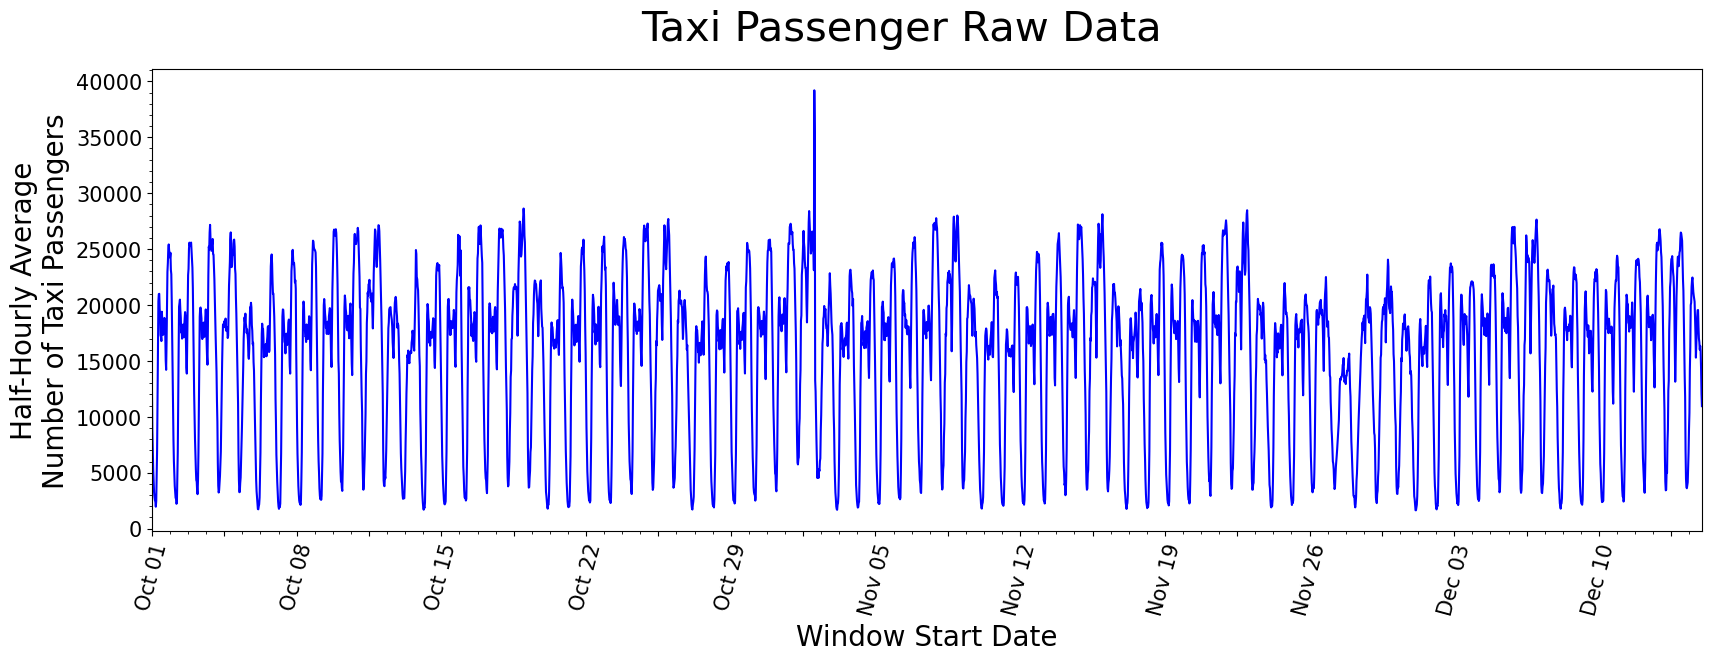

In [31]:
plot_data()

Found anomalies at: 
 [1538]


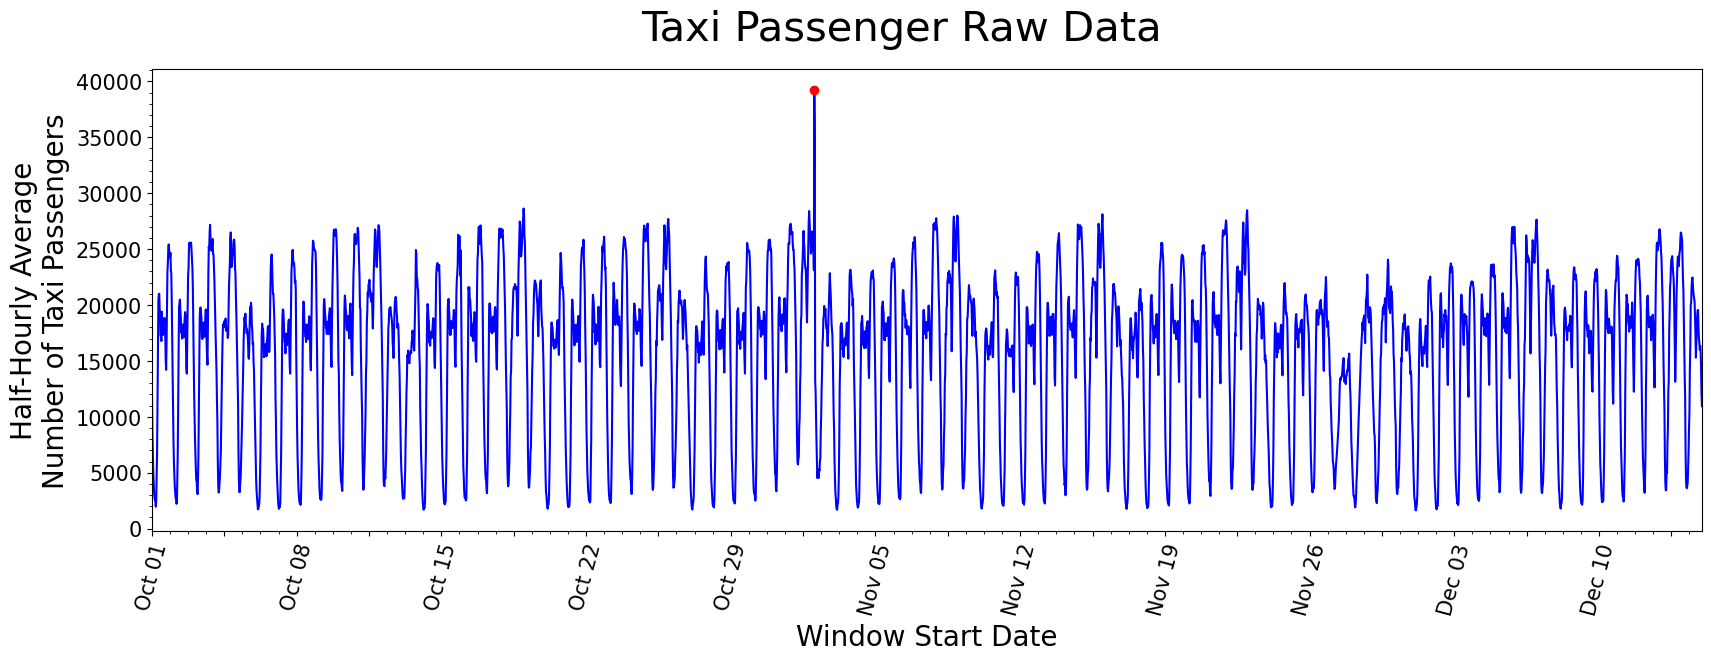

In [32]:
mean_value = np.mean(taxi_df['value'])
std_value = np.std(taxi_df['value'])

mask = np.logical_or(
    taxi_df['value'] > mean_value + 3 * std_value,
    taxi_df['value'] < mean_value - 3 * std_value,
)

IDX = np.flatnonzero(mask)
print(f'Found anomalies at: \n', IDX)

plot_data(IDX)